IRIS DATASET
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

  Species  
0  setosa  
1  setosa  
2  setosa  
3  setosa  
4  setosa  

ACTUAL SPECIES:
['setosa' 'virginica' 'versicolor' 'versicolor' 'setosa' 'versicolor'
 'setosa' 'setosa' 'virginica' 'versicolor' 'virginica' 'virginica'
 'virginica' 'versicolor' 'setosa' 'setosa' 'setosa' 'versicolor'
 'versicolor' 'virginica' 'setosa' 'virginica' 'versicolor' 'virginica'
 'virginica' 'versicolor' 'versicolor' 'setosa' 'virginica' 'setosa']

PREDICTED SPECIES:
['setosa' 'virginica' 'versicolor' 'versicolor' 'setosa' 

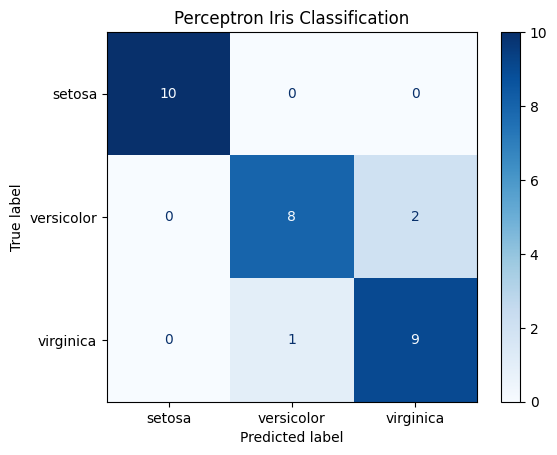


CLASSIFICATION REPORT:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.89      0.80      0.84        10
   virginica       0.82      0.90      0.86        10

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30


NEW FLOWER PREDICTION:
Predicted Species: setosa

Program executed successfully!


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


In [19]:

# Perceptron-Based Iris Classification

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Perceptron
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.metrics import ConfusionMatrixDisplay

# Step 1: Load the Iris dataset
iris = load_iris()
X = iris.data
y = iris.target

df = pd.DataFrame(X, columns=iris.feature_names)
df["Species"] = [iris.target_names[i] for i in y]

print("IRIS DATASET")
print(df.head())

# Step 2: Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Step 3: Create a Perceptron model
# Scaling helps the model learn more effectively
model = make_pipeline(
    StandardScaler(),
    Perceptron(max_iter=2000, eta0=0.01, random_state=42)
)

# Step 4: Train the model
model.fit(X_train, y_train)

# Step 5: Predict flower species
y_pred = model.predict(X_test)

print("\nACTUAL SPECIES:")
print(iris.target_names[y_test])

print("\nPREDICTED SPECIES:")
print(iris.target_names[y_pred])

# Step 6: Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print("\nModel Accuracy:", round(accuracy * 100, 2), "%")

# Step 7: Display confusion matrix
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=iris.target_names
)
disp.plot(cmap="Blues")
plt.title("Perceptron Iris Classification")
plt.show()

# Step 8: Display classification report
print("\nCLASSIFICATION REPORT:")
print(classification_report(
    y_test, y_pred,
    target_names=iris.target_names,
    zero_division=0
))

# Step 9: Predict a new flower
new_flower = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2]],
    columns=iris.feature_names
)

prediction = model.predict(new_flower)[0]

print("\nNEW FLOWER PREDICTION:")
print("Predicted Species:", iris.target_names[prediction])

print("\nProgram executed successfully!")
